# 1-stage → 凍結2-stage：感度・特異度の変化

主比較はSpatial S34 M04→M06、HyperAdapt M08→M10。M01（同seedの親ResNet ERM）、M03・M07（各モデルERM）を補助対照とする。global class weight、seed 42–44、race-known test、best validation AUROC、固定argmax。凍結単独の因果効果ではなく30対30+30epochの手順差を調べる。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rootutils
from IPython.display import display

ROOT = rootutils.setup_root(Path.cwd(), indicator=".project-root", pythonpath=True)
from analysis.common.paths import STYLE_SHEET, study_dir  # noqa: E402
from analysis.archive.race_known_architecture_objective_comparison.comparison import (  # noqa: E402
    GROUP_LABELS,
    evaluate,
    group_ids,
    paired_deltas,
    plot_q,
    prediction_command,
    read_predictions,
    read_q_history,
    select_runs,
)
from analysis.archive.race_known_architecture_objective_comparison.operating_point import (  # noqa: E402
    gap_extrema,
    paired_group_changes,
    prediction_transitions,
    summarize_best_q,
)

plt.style.use(STYLE_SHEET)
PACKAGE = study_dir("race_known_architecture_objective_comparison")
TOPIC = "07_two_stage_operating_point"
SEEDS = [42, 43, 44]
CONDITIONS = {
    "M01": "resnet-chexpert-race-known",
    "M03": "spatial-lora-chexpert-race-known",
    "M04": "spatial-lora-chexpert-age-race-group-dro-race-known",
    "M06": "spatial-lora-chexpert-from-resnet-age-race-group-dro-race-known",
    "M07": "hyperadapt-chexpert-race-known",
    "M08": "hyperadapt-chexpert-age-race-group-dro-race-known",
    "M10": "hyperadapt-chexpert-from-resnet-age-race-group-dro-race-known",
}
PAIRS = [["M04", "M06"], ["M08", "M10"]]
PANELS = {
    "Spatial S34": {"M01": "Parent ResNet ERM", "M03": "Spatial ERM", "M04": "DRO 1-stage", "M06": "DRO 2-stage"},
    "HyperAdapt": {"M01": "Parent ResNet ERM", "M07": "HyperAdapt ERM", "M08": "DRO 1-stage", "M10": "DRO 2-stage"},
}
RESULTS, FIGURES = PACKAGE / "results" / TOPIC, PACKAGE / "figures" / TOPIC
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

## 入力と全体指標

checkpoint・split・親runを共通処理で検証する。cacheが不足する場合だけ提示コマンドで生成する。予測生成・学習は自動起動しない。

In [2]:
provenance, frame, directories = select_runs(PACKAGE, CONDITIONS, SEEDS)
assert len(provenance) == 21
assert provenance.class_weight_scope.eq("global").all()
for row in provenance.itertuples():
    assert row.objective == ("erm" if row.condition in {"M01", "M03", "M07"} else "group_dro_global")
    assert bool(row.freeze_backbone) == (row.condition in {"M06", "M10"})
print(prediction_command(PACKAGE, directories))
caches = read_predictions(PACKAGE, directories, frame)
summary, subgroup = evaluate(caches, frame)
delta = paired_deltas(summary, PAIRS)
provenance.to_csv(RESULTS / "provenance.csv", index=False)
summary.to_csv(RESULTS / "metrics_by_seed.csv", index=False)
subgroup.to_csv(RESULTS / "subgroup_by_seed.csv", index=False)
delta.groupby("pair").agg({name: ["mean", "std"] for name in ["bacc", "worst_bacc", "Eopp0", "Eopp1"]}).to_csv(
    RESULTS / "paired_delta_mean_std.csv"
)
display(summary.groupby("condition")[["auroc", "bacc", "worst_bacc", "Eopp0", "Eopp1"]].agg(["mean", "std"]))
display(subgroup[subgroup.condition == "M01"][["group", "n_positive", "n_negative"]].drop_duplicates())

auroc                bacc           worst_bacc            \
               mean       std      mean       std       mean       std   
condition                                                                
M01        0.861218  0.003373  0.794593  0.000368   0.654425  0.002885   
M03        0.862125  0.000861  0.792037  0.007512   0.645892  0.034128   
M04        0.855151  0.001696  0.783232  0.000796   0.661300  0.003590   
M06        0.864267  0.001938  0.797981  0.000791   0.652987  0.007701   
M07        0.860977  0.000650  0.792615  0.001586   0.655417  0.016523   
M08        0.853638  0.002622  0.786775  0.005410   0.662759  0.030151   
M10        0.863329  0.002582  0.798010  0.003115   0.652955  0.004975   

              Eopp0               Eopp1            
               mean       std      mean       std  
condition                                          
M01        0.209649  0.011526  0.472789  0.013068  
M03        0.223677  0.026917  0.486003  0.115324  
M04        0.243849  0.020448  0.463892  0.022284  
M06        0.188052  0.001711  0.470612  0.012161  
M07        0.220878  0.010265  0.478082  0.031439  
M08        0.216975  0.025095  0.440754  0.082369  
M10        0.201812  0.018804  0.473771  0.030637

,group,n_positive,n_negative
0,<65 × White,823,5339
1,<65 × Asian,186,980
2,<65 × Black,126,766
3,<65 × Others,402,2064
4,≥65 × White,365,5961
5,≥65 × Asian,52,1009
6,≥65 × Black,22,303
7,≥65 × Others,68,1151


## ① 群別TPR・TNRとgapの両端

絶対値にはERM対照を重ねる。差は同seedの2-stage−1-stage（点：各seed、線：平均±標準偏差）。gapの最大・最小群はseedごとに特定し、同率の群も残す。

delta_tpr           delta_tnr            \
                                         mean       std      mean       std   
pair      group_id group                                                      
M04 → M06 0        <65 × White  -1.903605e-02  0.020416  0.070987  0.021900   
          1        <65 × Asian  -4.301075e-02  0.042673  0.078912  0.029686   
          2        <65 × Black  -1.322751e-02  0.012123  0.044822  0.019942   
          3        <65 × Others -1.160862e-02  0.022434  0.044897  0.028010   
          4        ≥65 × White  -3.926941e-02  0.072968  0.045071  0.042180   
          5        ≥65 × Asian  -3.846154e-02  0.033309  0.049224  0.032059   
          6        ≥65 × Black  -3.700743e-17  0.045455  0.039604  0.045850   
          7        ≥65 × Others -3.921569e-02  0.042452  0.022589  0.043021   
M08 → M10 0        <65 × White   7.695423e-03  0.015811  0.015733  0.037430   
          1        <65 × Asian   2.688172e-02  0.023435  0.018367  0.027627   
          2        <65 × Black  -5.291005e-03  0.024246  0.008703  0.047383   
          3        <65 × Others  1.658375e-02  0.018336 -0.002584  0.013826   
          4        ≥65 × White   2.648402e-02  0.084902  0.005312  0.054362   
          5        ≥65 × Asian   3.205128e-02  0.072807 -0.000991  0.040779   
          6        ≥65 × Black   9.090909e-02  0.120261  0.028603  0.055356   
          7        ≥65 × Others -1.960784e-02  0.080994  0.000000  0.035430   

                                delta_bacc            
                                      mean       std  
pair      group_id group                              
M04 → M06 0        <65 × White    0.025976  0.003718  
          1        <65 × Asian    0.017950  0.015205  
          2        <65 × Black    0.015797  0.008702  
          3        <65 × Others   0.016644  0.005146  
          4        ≥65 × White    0.002901  0.015542  
          5        ≥65 × Asian    0.005381  0.000804  
          6        ≥65 × Black    0.019802  0.043642  
          7        ≥65 × Others  -0.008313  0.004347  
M08 → M10 0        <65 × White    0.011714  0.011184  
          1        <65 × Asian    0.022625  0.020427  
          2        <65 × Black    0.001706  0.011910  
          3        <65 × Others   0.007000  0.008347  
          4        ≥65 × White    0.015898  0.016503  
          5        ≥65 × Asian    0.015530  0.018049  
          6        ≥65 × Black    0.059756  0.045349  
          7        ≥65 × Others  -0.009804  0.025255

,condition,seed,metric,minimum,maximum,gap,minimum_groups,maximum_groups
0,M01,42,tpr,0.455882,0.914945,0.459063,≥65 × Others,<65 × White
1,M01,42,tnr,0.657143,0.854909,0.197766,<65 × Asian,≥65 × Others
2,M01,43,tpr,0.455882,0.930108,0.474225,≥65 × Others,<65 × Asian
3,M01,43,tnr,0.636735,0.857515,0.220781,<65 × Asian,≥65 × Others
4,M01,44,tpr,0.397059,0.882139,0.485080,≥65 × Others,<65 × White
5,M01,44,tnr,0.694898,0.905300,0.210402,<65 × Asian,≥65 × Others
6,M03,42,tpr,0.558824,0.936817,0.377993,≥65 × Others,<65 × White
7,M03,42,tnr,0.592857,0.793223,0.200366,<65 × Asian,≥65 × Others
8,M03,43,tpr,0.294118,0.901580,0.607462,≥65 × Others,<65 × White
9,M03,43,tnr,0.670408,0.923545,0.253137,<65 × Asian,≥65 × Others


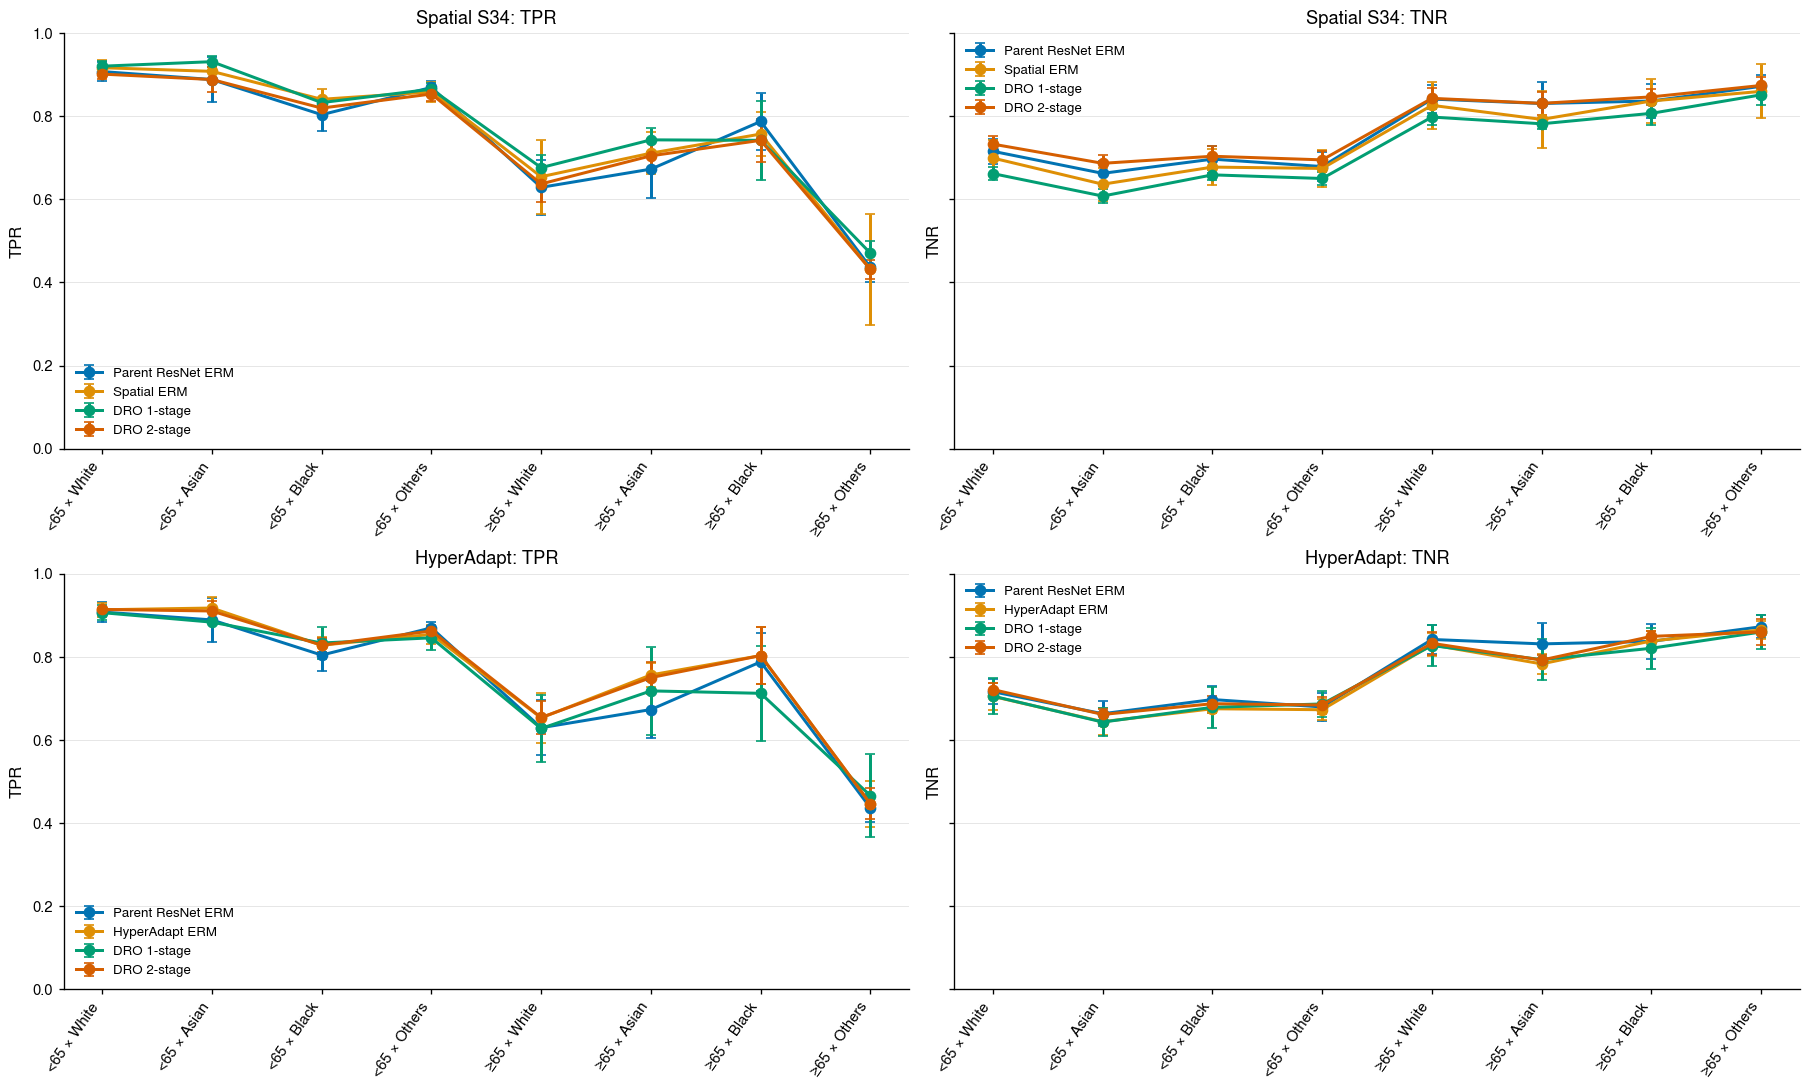

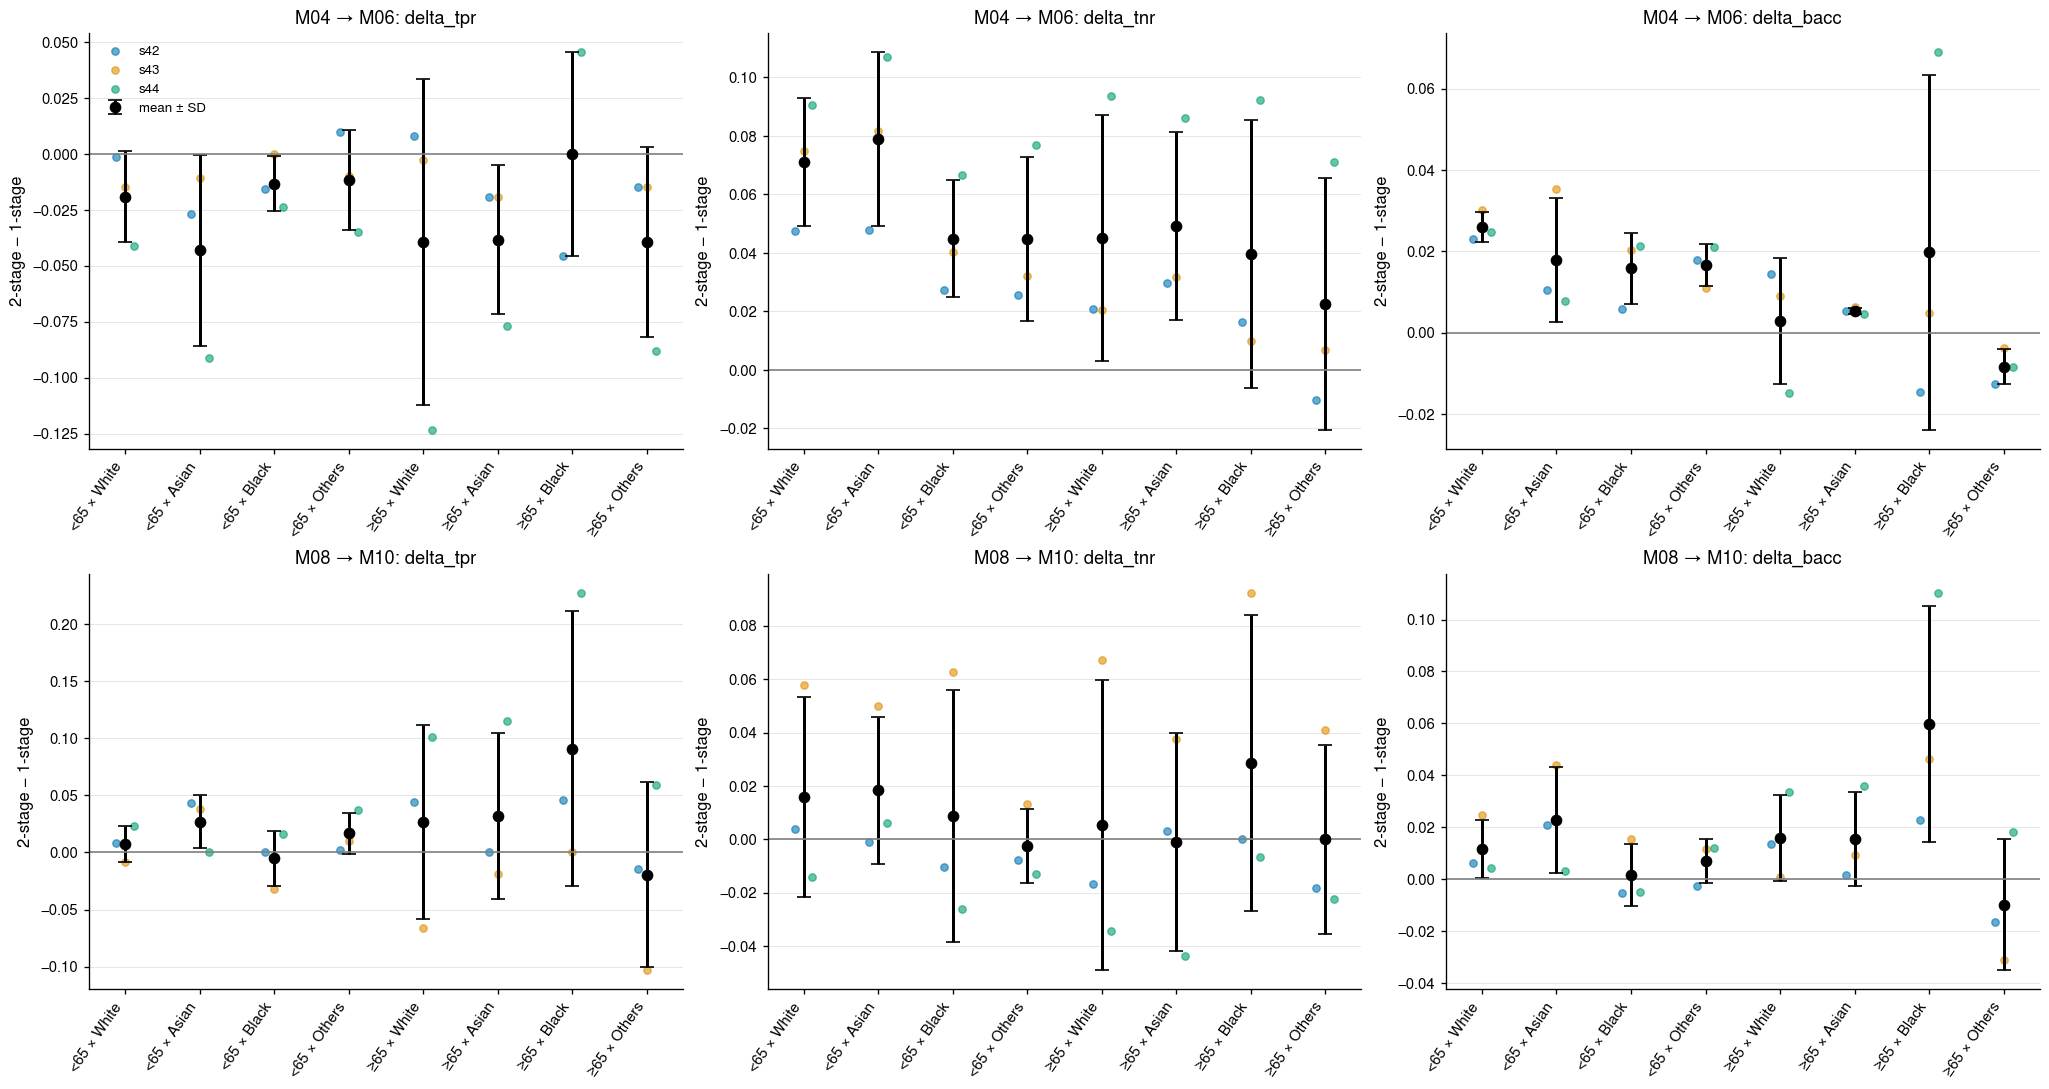

In [3]:
changes = paired_group_changes(subgroup, PAIRS)
extrema = gap_extrema(subgroup)
changes.to_csv(RESULTS / "group_changes_by_seed.csv", index=False)
extrema.to_csv(RESULTS / "gap_extrema_by_seed.csv", index=False)
change_stats = changes.groupby(["pair", "group_id", "group"])[["delta_tpr", "delta_tnr", "delta_bacc"]].agg(
    ["mean", "std"]
)
change_stats.to_csv(RESULTS / "group_changes_mean_std.csv")
display(change_stats)
display(extrema)

fig, axes = plt.subplots(2, 2, figsize=(15, 9), layout="constrained", sharey=True)
for row, (model, conditions) in enumerate(PANELS.items()):
    for col, metric in enumerate(["tpr", "tnr"]):
        ax = axes[row, col]
        for condition, label in conditions.items():
            stats = subgroup[subgroup.condition == condition].groupby("group_id")[metric].agg(["mean", "std"])
            ax.errorbar(stats.index, stats["mean"], yerr=stats["std"], marker="o", capsize=3, label=label)
        ax.set(title=f"{model}: {metric.upper()}", ylim=(0, 1), ylabel=metric.upper())
        ax.set_xticks(range(8), GROUP_LABELS, rotation=55, ha="right")
        ax.legend(fontsize=8)
fig.savefig(FIGURES / "group_tpr_tnr.png", dpi=160)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(17, 9), layout="constrained")
for row, (baseline, treatment) in enumerate(PAIRS):
    pair = f"{baseline} → {treatment}"
    selected = changes[changes.pair == pair]
    for col, metric in enumerate(["delta_tpr", "delta_tnr", "delta_bacc"]):
        ax = axes[row, col]
        stats = selected.groupby("group_id")[metric].agg(["mean", "std"])
        ax.errorbar(stats.index, stats["mean"], yerr=stats["std"], fmt="o", color="black", capsize=4, label="mean ± SD")
        for offset, seed in zip([-0.12, 0, 0.12], SEEDS, strict=True):
            data = selected[selected.seed == seed]
            ax.scatter(data.group_id + offset, data[metric], s=20, alpha=0.6, label=f"s{seed}")
        ax.axhline(0, color="grey", linewidth=1)
        ax.set(title=f"{pair}: {metric}", ylabel="2-stage − 1-stage")
        ax.set_xticks(range(8), GROUP_LABELS, rotation=55, ha="right")
        if row == 0 and col == 0:
            ax.legend(fontsize=8)
fig.savefig(FIGURES / "group_rate_deltas.png", dpi=160)
plt.show()

## ② 全体BACCへの寄与

群の陽性数/N陽性×ΔTPR/2、陰性数/N陰性×ΔTNR/2を分けて表示する。8群でtest全件を覆うこと、寄与の和が全体BACC差になることを検算する。群平均BACCは各群を均等に扱う補助指標。

tpr_contribution  tnr_contribution  bacc_contribution  \
pair      seed                                                          
M04 → M06 42           -0.000978          0.014824           0.013845   
          43           -0.005137          0.021140           0.016003   
          44           -0.029843          0.044244           0.014401   
M08 → M10 42            0.007828         -0.003528           0.004300   
          43           -0.007828          0.026916           0.019089   
          44            0.021526         -0.011210           0.010316   

                macro_bacc_contribution  observed_bacc_delta  
pair      seed                                                
M04 → M06 42                   0.006241             0.013845  
          43                   0.014140             0.016003  
          44                   0.015670             0.014401  
M08 → M10 42                   0.005056             0.004300  
          43                   0.015064             0.019089  
          44                   0.026540             0.010316

,mean,std
condition,,
M01,0.758473,0.005619
M03,0.755500,0.003173
M04,0.750362,0.005548
M06,0.762379,0.003400
M07,0.761406,0.005197
M08,0.750402,0.013127
M10,0.765955,0.003439


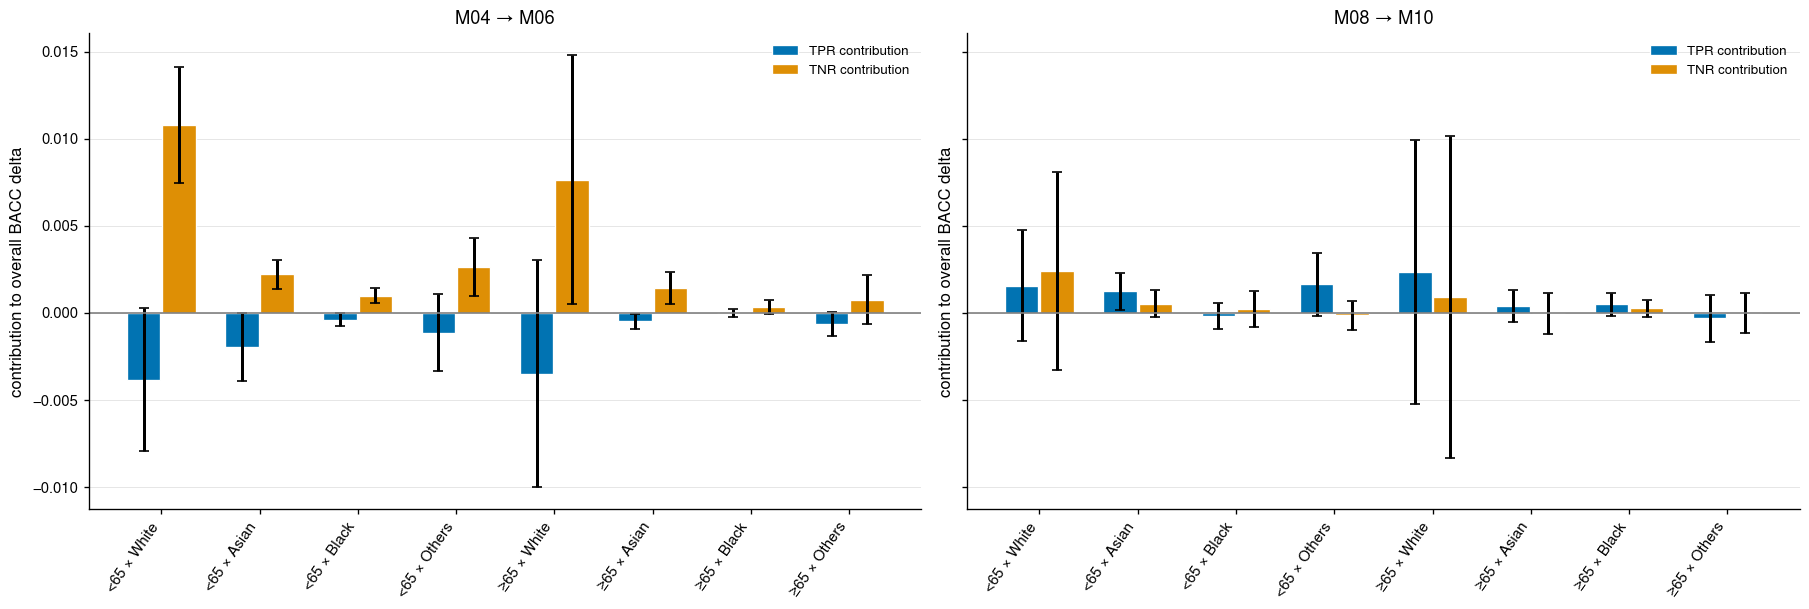

In [4]:
assert (group_ids(frame) >= 0).all(), "8群外の症例があり、分解に追加群が必要"
contributions = changes.groupby(["pair", "seed"])[
    ["tpr_contribution", "tnr_contribution", "bacc_contribution", "macro_bacc_contribution"]
].sum()
observed = delta.set_index(["pair", "seed"]).bacc.reindex(contributions.index)
np.testing.assert_allclose(contributions.bacc_contribution, observed, atol=1e-12)
contributions["observed_bacc_delta"] = observed
contributions.to_csv(RESULTS / "bacc_decomposition_by_seed.csv")
display(contributions)
macro = subgroup.groupby(["condition", "seed"]).bacc.mean().rename("macro_bacc")
macro.to_csv(RESULTS / "macro_bacc_by_seed.csv")
display(macro.groupby("condition").agg(["mean", "std"]))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), layout="constrained", sharey=True)
for ax, (baseline, treatment) in zip(axes, PAIRS, strict=True):
    pair = f"{baseline} → {treatment}"
    stats = (
        changes[changes.pair == pair].groupby("group_id")[["tpr_contribution", "tnr_contribution"]].agg(["mean", "std"])
    )
    for offset, metric, label in [
        (-0.18, "tpr_contribution", "TPR contribution"),
        (0.18, "tnr_contribution", "TNR contribution"),
    ]:
        ax.bar(
            stats.index + offset, stats[metric]["mean"], width=0.34, yerr=stats[metric]["std"], capsize=3, label=label
        )
    ax.axhline(0, color="grey", linewidth=1)
    ax.set(title=pair, ylabel="contribution to overall BACC delta")
    ax.set_xticks(range(8), GROUP_LABELS, rotation=55, ha="right")
    ax.legend(fontsize=8)
fig.savefig(FIGURES / "bacc_contributions.png", dpi=160)
plt.show()

## ③ 同じ症例の判定変更

陽性はFN→TPとTP→FN、陰性はFP→TNとTN→FPを数える。正味改善件数/ラベル件数がΔTPR・ΔTNRと一致することを検算する。件数は群サイズに依存するため、率と併読する。

FN_to_TP              TP_to_FN             \
                                      mean        std       mean        std   
pair      group_id group                                                      
M04 → M06 0        <65 × White   11.000000   8.660254  26.666667  11.718931   
          1        <65 × Asian    2.000000   1.732051  10.000000   6.244998   
          2        <65 × Black    2.000000   1.000000   3.666667   0.577350   
          3        <65 × Others   9.333333   9.237604  14.000000   5.291503   
          4        ≥65 × White   18.333333  11.590226  32.666667  16.072751   
          5        ≥65 × Asian    1.000000   0.000000   3.000000   1.732051   
          6        ≥65 × Black    2.000000   1.000000   2.000000   1.000000   
          7        ≥65 × Others   3.666667   1.154701   6.333333   2.516611   
M08 → M10 0        <65 × White   19.000000   7.549834  12.666667   5.507571   
          1        <65 × Asian    8.666667   1.527525   3.666667   3.055050   
          2        <65 × Black    3.666667   2.516611   4.333333   0.577350   
          3        <65 × Others  14.666667   5.033223   8.000000   2.645751   
          4        ≥65 × White   30.000000  15.524175  20.333333  16.289056   
          5        ≥65 × Asian    4.000000   2.645751   2.333333   1.154701   
          6        ≥65 × Black    3.333333   2.309401   1.333333   0.577350   
          7        ≥65 × Others   4.333333   1.527525   5.666667   4.725816   

                                   FP_to_TN                TN_to_FP  \
                                       mean         std        mean   
pair      group_id group                                              
M04 → M06 0        <65 × White   461.666667   71.696118   82.666667   
          1        <65 × Asian    95.666667   18.556221   18.333333   
          2        <65 × Black    53.000000    8.717798   18.666667   
          3        <65 × Others  145.333333   36.170891   52.666667   
          4        ≥65 × White   413.000000  162.923295  144.333333   
          5        ≥65 × Asian    77.000000   25.159491   27.333333   
          6        ≥65 × Black    20.666667    7.637626    8.666667   
          7        ≥65 × Others   60.666667   33.201406   34.666667   
M08 → M10 0        <65 × White   281.333333  147.585004  197.333333   
          1        <65 × Asian    57.333333   21.455380   39.333333   
          2        <65 × Black    39.333333   24.378953   32.666667   
          3        <65 × Others   89.333333   19.655364   94.666667   
          4        ≥65 × White   275.666667  212.071529  244.000000   
          5        ≥65 × Asian    50.333333   28.023799   51.333333   
          6        ≥65 × Black    20.333333   15.502688   11.666667   
          7        ≥65 × Others   50.333333   28.041636   50.333333   

                                            net_positive             \
                                        std         mean        std   
pair      group_id group                                              
M04 → M06 0        <65 × White    46.003623   -15.666667  16.802778   
          1        <65 × Asian    11.150486    -8.000000   7.937254   
          2        <65 × Black     7.023769    -1.666667   1.527525   
          3        <65 × Others   21.733231    -4.666667   9.018500   
          4        ≥65 × White    88.861315   -14.333333  26.633312   
          5        ≥65 × Asian     7.234178    -2.000000   1.732051   
          6        ≥65 × Black     6.806859     0.000000   1.000000   
          7        ≥65 × Others   18.556221    -2.666667   2.886751   
M08 → M10 0        <65 × White    53.266625     6.333333  13.012814   
          1        <65 × Asian     5.686241     5.000000   4.358899   
          2        <65 × Black    11.930353    -0.666667   3.055050   
          3        <65 × Others    9.504385     6.666667   7.371115   
          4        ≥65 × White   112.066944     9.666667  30.989245   
          5        ≥65 × Asian    13.796135   

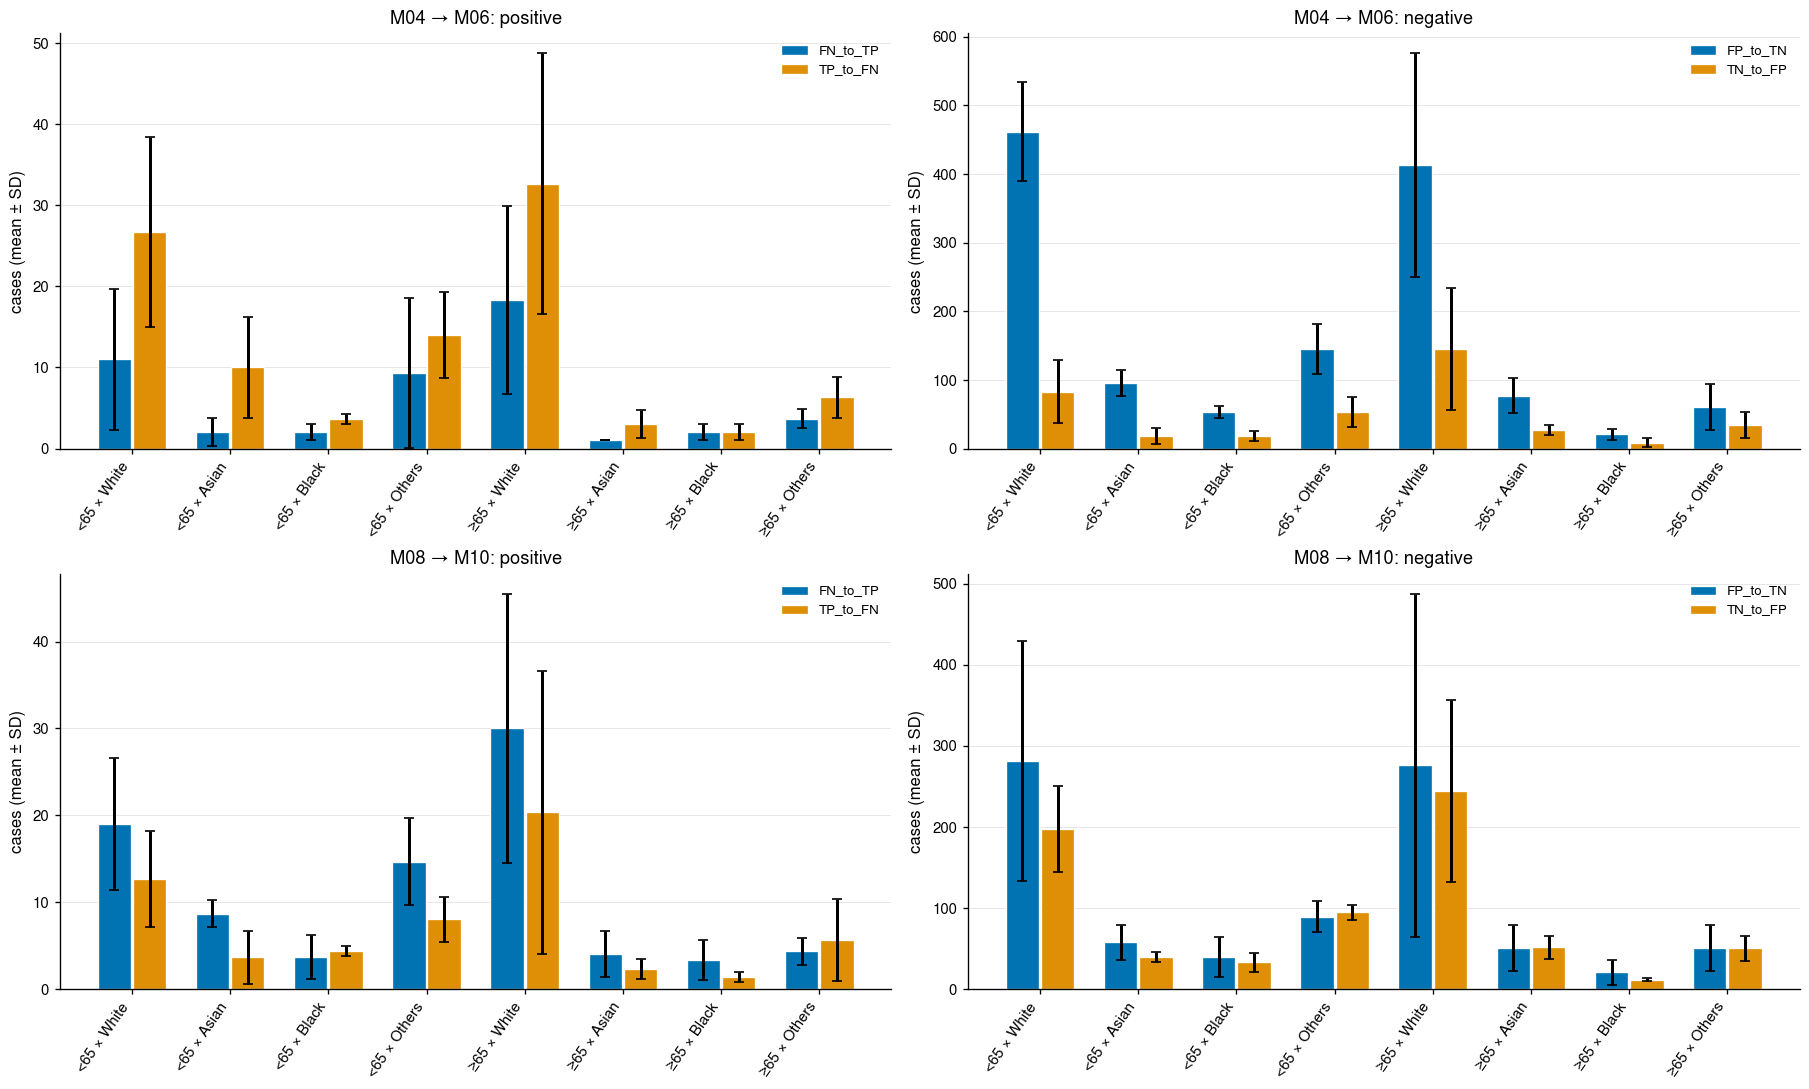

In [5]:
transitions = prediction_transitions(caches, frame, PAIRS, SEEDS)
matched = transitions.merge(
    changes, on=["pair", "seed", "group_id", "group"], validate="one_to_one", suffixes=("", "_rates")
)
for metric, label in [("tpr", "positive"), ("tnr", "negative")]:
    np.testing.assert_allclose(matched[f"net_{label}"] / matched[f"n_{label}"], matched[f"delta_{metric}"], atol=1e-12)
transitions.to_csv(RESULTS / "prediction_transitions_by_seed.csv", index=False)
transition_stats = transitions.groupby(["pair", "group_id", "group"])[
    ["FN_to_TP", "TP_to_FN", "FP_to_TN", "TN_to_FP", "net_positive", "net_negative"]
].agg(["mean", "std"])
transition_stats.to_csv(RESULTS / "prediction_transitions_mean_std.csv")
display(transition_stats)

fig, axes = plt.subplots(2, 2, figsize=(15, 9), layout="constrained")
for row, (baseline, treatment) in enumerate(PAIRS):
    pair = f"{baseline} → {treatment}"
    stats = transitions[transitions.pair == pair].groupby("group_id")
    for col, (improved, worsened, label) in enumerate(
        [("FN_to_TP", "TP_to_FN", "positive"), ("FP_to_TN", "TN_to_FP", "negative")]
    ):
        ax = axes[row, col]
        ax.bar(
            np.arange(8) - 0.18,
            stats[improved].mean(),
            width=0.34,
            yerr=stats[improved].std(),
            capsize=3,
            label=improved,
        )
        ax.bar(
            np.arange(8) + 0.18,
            stats[worsened].mean(),
            width=0.34,
            yerr=stats[worsened].std(),
            capsize=3,
            label=worsened,
        )
        ax.set(title=f"{pair}: {label}", ylabel="cases (mean ± SD)")
        ax.set_xticks(range(8), GROUP_LABELS, rotation=55, ha="right")
        ax.legend(fontsize=8)
fig.savefig(FIGURES / "prediction_transitions.png", dpi=160)
plt.show()

## ④ 学習中のqと群別性能の変化

DROの12runを対象に、best epochまで（当該epochを含む）のq_meanをepoch等重みで平均し、bestのq_endも併記する。q_meanは各train forwardの更新後qのbatch平均。1-stage→2-stageのΔqとΔTPR/TNR/BACCを照合し、親ERM→2-stageの変化とは分ける。qはweighted CEへの重みで、感度専用の重み・勾配寄与ではない。

,condition,seed,best_epoch,epochs_to_best
0,M04,42,9,10
8,M04,43,8,9
16,M04,44,8,9
24,M06,42,3,4
32,M06,43,7,8
40,M06,44,9,10
48,M08,42,17,18
56,M08,43,22,23
64,M08,44,9,10
72,M10,42,11,12


q_mean_to_best_1stage            \
                                                 mean       std   
pair      group_id group                                          
M04 → M06 0        <65 × White               0.237351  0.009039   
          1        <65 × Asian               0.198016  0.006815   
          2        <65 × Black               0.107776  0.006426   
          3        <65 × Others              0.348022  0.004420   
          4        ≥65 × White               0.026408  0.001775   
          5        ≥65 × Asian               0.028693  0.001767   
          6        ≥65 × Black               0.022444  0.000365   
          7        ≥65 × Others              0.031290  0.003069   
M08 → M10 0        <65 × White               0.326806  0.087500   
          1        <65 × Asian               0.165492  0.024914   
          2        <65 × Black               0.080943  0.026985   
          3        <65 × Others              0.359058  0.020619   
          4        ≥65 × White               0.016299  0.007425   
          5        ≥65 × Asian               0.018410  0.007452   
          6        ≥65 × Black               0.013963  0.006405   
          7        ≥65 × Others              0.019028  0.008579   

                                q_mean_to_best_2stage            \
                                                 mean       std   
pair      group_id group                                          
M04 → M06 0        <65 × White               0.198136  0.010195   
          1        <65 × Asian               0.210084  0.006019   
          2        <65 × Black               0.115845  0.020548   
          3        <65 × Others              0.304401  0.076060   
          4        ≥65 × White               0.040992  0.017394   
          5        ≥65 × Asian               0.045997  0.017463   
          6        ≥65 × Black               0.035432  0.016635   
          7        ≥65 × Others              0.049113  0.018542   
M08 → M10 0        <65 × White               0.205236  0.012267   
          1        <65 × Asian               0.220101  0.014898   
          2        <65 × Black               0.102005  0.018981   
          3        <65 × Others              0.351239  0.038619   
          4        ≥65 × White               0.029020  0.008977   
          5        ≥65 × Asian               0.034276  0.009237   
          6        ≥65 × Black               0.023309  0.007254   
          7        ≥65 × Others              0.034814  0.009885   

                                delta_q_mean_to_best            \
                                                mean       std   
pair      group_id group                                         
M04 → M06 0        <65 × White             -0.039215  0.018960   
          1        <65 × Asian              0.012068  0.011757   
          2        <65 × Black              0.008069  0.022988   
          3        <65 × Others            -0.043621  0.076478   
          4        ≥65 × White              0.014584  0.019118   
          5        ≥65 × Asian              0.017304  0.019137   
          6        ≥65 × Black              0.012988  0.016596   
          7        ≥65 × Others             0.017822  0.021610   
M08 → M10 0        <65 × White             -0.121570  0.092788   
          1        <65 × Asian              0.054608  0.037679   
          2        <65 × Black              0.021063  0.010107   
          3        <65 × Others            -0.007819  0.046599   
          4        ≥65 × White              0.012720  0.003211   
          5        ≥65 × Asian              0.015866  0.003735   
          6        ≥65 × Black              0.009346  0.001538   
          7        ≥65 × Others             0.015786  0.002778   

                                q_end_at_best_1stage            \
                                                mean       std   
pair      group_id group                                         
M04 → M06 0        <65 × White 

q_mean_to_best           delta_tpr            \
                                          mean       std      mean       std   
pair      group_id group                                                       
M01 → M06 0        <65 × White        0.198136  0.010195 -0.006075  0.010800   
          1        <65 × Asian        0.210084  0.006019  0.000000  0.024638   
          2        <65 × Black        0.115845  0.020548  0.015873  0.020998   
          3        <65 × Others       0.304401  0.076060 -0.015755  0.007600   
          4        ≥65 × White        0.040992  0.017394  0.008219  0.021398   
          5        ≥65 × Asian        0.045997  0.017463  0.032051  0.040032   
          6        ≥65 × Black        0.035432  0.016635 -0.045455  0.045455   
          7        ≥65 × Others       0.049113  0.018542 -0.004902  0.022464   
M01 → M10 0        <65 × White        0.205236  0.012267  0.006075  0.020763   
          1        <65 × Asian        0.220101  0.014898  0.021505  0.029934   
          2        <65 × Black        0.102005  0.018981  0.023810  0.028615   
          3        <65 × Others       0.351239  0.038619 -0.007463  0.010843   
          4        ≥65 × White        0.029020  0.008977  0.024658  0.068164   
          5        ≥65 × Asian        0.034276  0.009237  0.076923  0.050880   
          6        ≥65 × Black        0.023309  0.007254  0.015152  0.131216   
          7        ≥65 × Others       0.034814  0.009885  0.009804  0.022464   

                                delta_tnr           delta_bacc            
                                     mean       std       mean       std  
pair      group_id group                                                  
M01 → M06 0        <65 × White   0.017232  0.010781   0.005578  0.001353  
          1        <65 × Asian   0.024150  0.012677   0.012075  0.008358  
          2        <65 × Black   0.006963  0.008393   0.011418  0.009012  
          3        <65 × Others  0.016150  0.012459   0.000198  0.008326  
          4        ≥65 × White   0.001789  0.010776   0.005004  0.005486  
          5        ≥65 × Asian   0.000330  0.023334   0.016191  0.013453  
          6        ≥65 × Black   0.009901  0.024917  -0.017777  0.029946  
          7        ≥65 × Others  0.002027  0.008571  -0.001437  0.008108  
M01 → M10 0        <65 × White   0.005120  0.021693   0.005597  0.003441  
          1        <65 × Asian  -0.001701  0.018405   0.009902  0.006315  
          2        <65 × Black  -0.010009  0.024295   0.006900  0.009245  
          3        <65 × Others  0.004683  0.015146  -0.001390  0.010326  
          4        ≥65 × White  -0.009227  0.036236   0.007715  0.017054  
          5        ≥65 × Asian  -0.038982  0.043981   0.018970  0.005905  
          6        ≥65 × Black   0.012101  0.036800   0.013626  0.055501  
          7        ≥65 × Others -0.012743  0.023334  -0.001469  0.002148

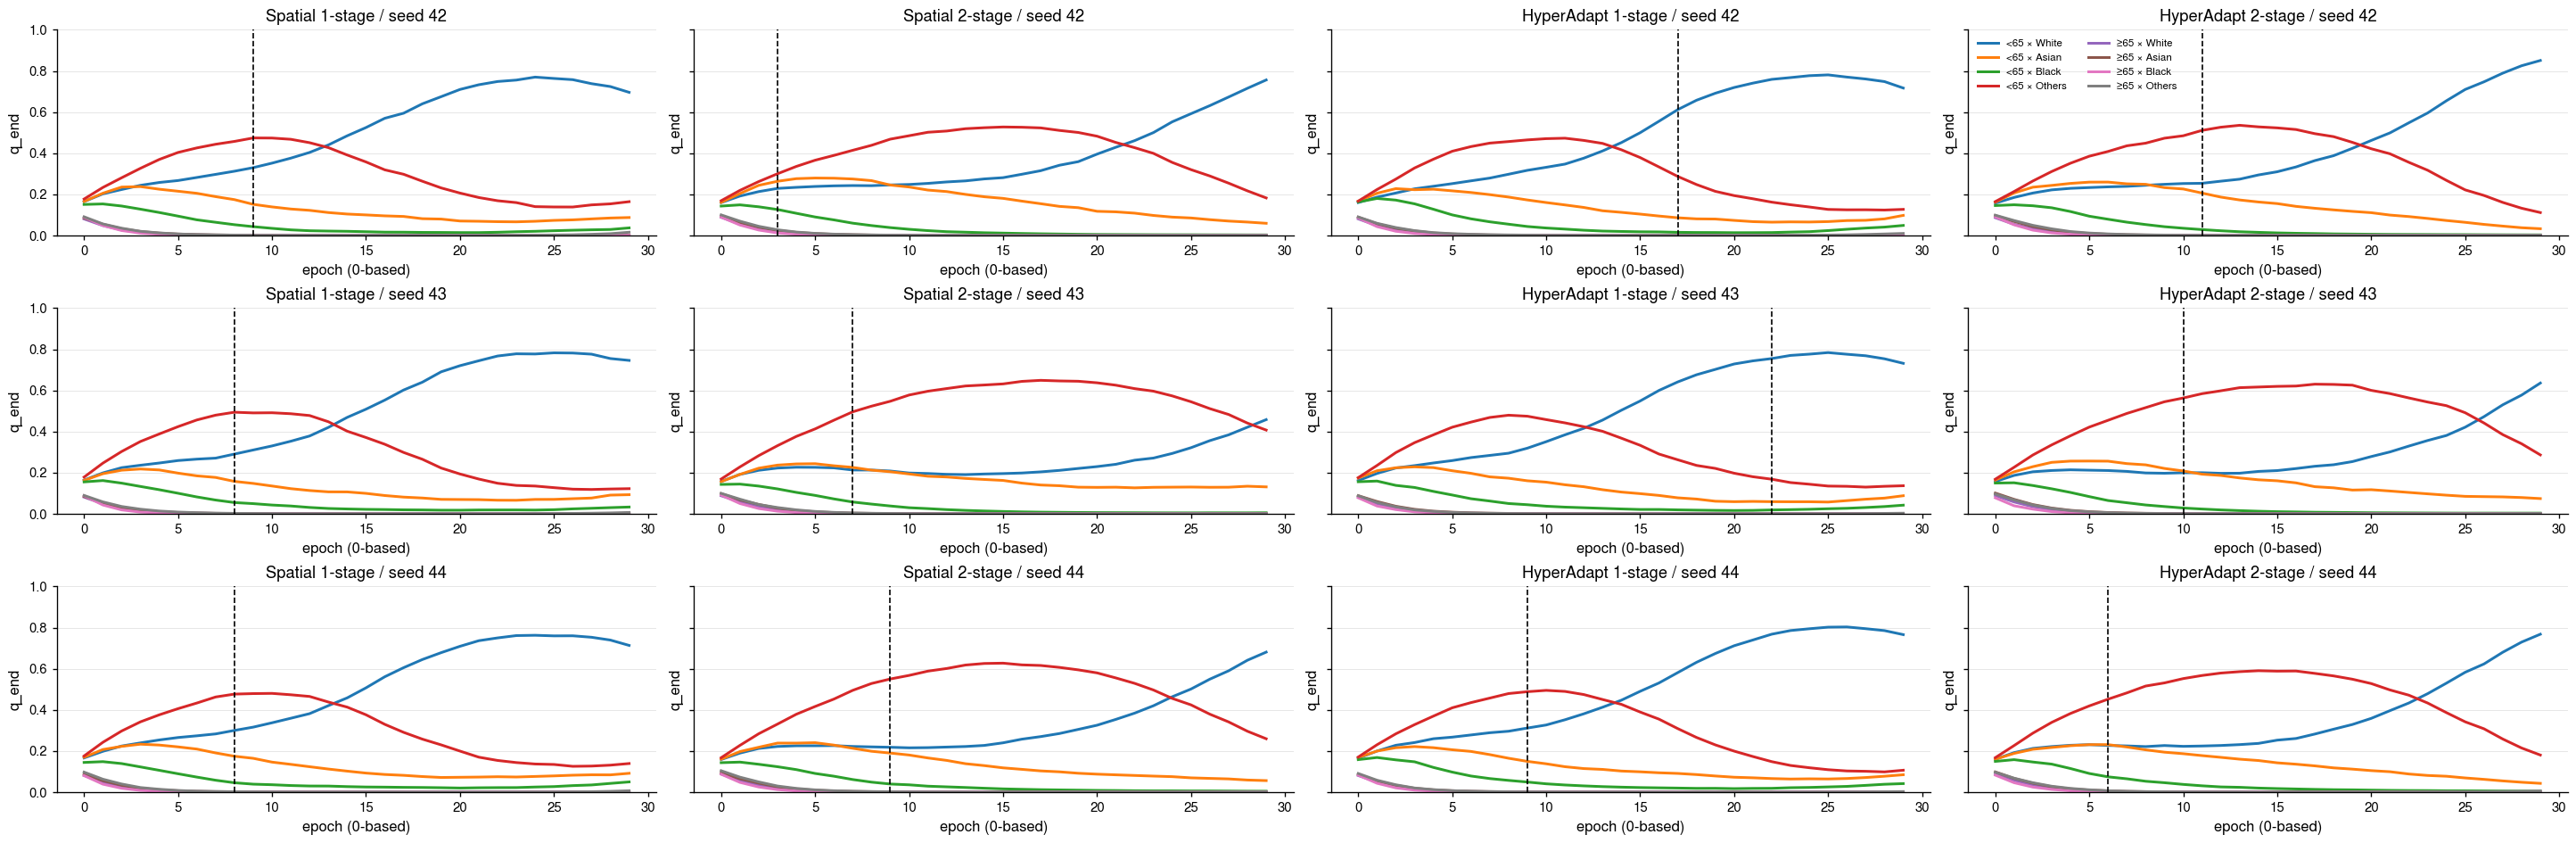

In [6]:
history = read_q_history(directories, provenance)
assert set(history.condition.unique()) == {"M04", "M06", "M08", "M10"}
q_summary = summarize_best_q(history)
np.testing.assert_allclose(q_summary.groupby(["condition", "seed"]).q_mean_to_best.sum(), 1, atol=1e-5)
history.to_csv(RESULTS / "q_history.csv", index=False)
q_summary.to_csv(RESULTS / "q_summary_to_best_by_seed.csv", index=False)
q_stats = q_summary.groupby(["condition", "group_id", "group"])[["q_mean_to_best", "q_end_at_best"]].agg(
    ["mean", "std"]
)
q_stats.to_csv(RESULTS / "q_summary_to_best_mean_std.csv")
display(q_summary[["condition", "seed", "best_epoch", "epochs_to_best"]].drop_duplicates())

comparison_rows = []
join_keys = ["seed", "group_id", "group"]
for baseline, treatment in PAIRS:
    left = q_summary[q_summary.condition == baseline].drop(columns="condition")
    right = q_summary[q_summary.condition == treatment].drop(columns="condition")
    joined = left.merge(right, on=join_keys, validate="one_to_one", suffixes=("_1stage", "_2stage"))
    joined["pair"] = f"{baseline} → {treatment}"
    joined["delta_q_mean_to_best"] = joined.q_mean_to_best_2stage - joined.q_mean_to_best_1stage
    comparison_rows.append(joined)
q_changes = pd.concat(comparison_rows, ignore_index=True).merge(changes, on=["pair", *join_keys], validate="one_to_one")
q_changes.to_csv(RESULTS / "q_vs_workflow_changes_by_seed.csv", index=False)
q_change_stats = q_changes.groupby(["pair", "group_id", "group"])[
    [
        "q_mean_to_best_1stage",
        "q_mean_to_best_2stage",
        "delta_q_mean_to_best",
        "q_end_at_best_1stage",
        "q_end_at_best_2stage",
        "delta_tpr",
        "delta_tnr",
        "delta_bacc",
    ]
].agg(["mean", "std"])
q_change_stats.to_csv(RESULTS / "q_vs_workflow_changes_mean_std.csv")
display(q_change_stats)

parent_changes = paired_group_changes(subgroup, [["M01", "M06"], ["M01", "M10"]])
parent_changes["condition"] = parent_changes.pair.map({"M01 → M06": "M06", "M01 → M10": "M10"})
q_parent = parent_changes.merge(q_summary, on=["condition", *join_keys], validate="one_to_one")
q_parent.to_csv(RESULTS / "q_vs_parent_changes_by_seed.csv", index=False)
display(
    q_parent.groupby(["pair", "group_id", "group"])[["q_mean_to_best", "delta_tpr", "delta_tnr", "delta_bacc"]].agg(
        ["mean", "std"]
    )
)

q_labels = {
    "M04": "Spatial 1-stage",
    "M06": "Spatial 2-stage",
    "M08": "HyperAdapt 1-stage",
    "M10": "HyperAdapt 2-stage",
}
fig = plot_q(history, q_labels)
fig.savefig(FIGURES / "q_history_by_seed.png", dpi=140)
plt.show()

### qの配分差と性能差

平均±標準偏差の配分図には均等重み1/8を示す。散布図は各seed×8群を別々の点で表示（色：群、○：seed42、□：43、△：44）。bestまでの期間はrunごとに異なる。相関・有意差・因果効果は主張しない。

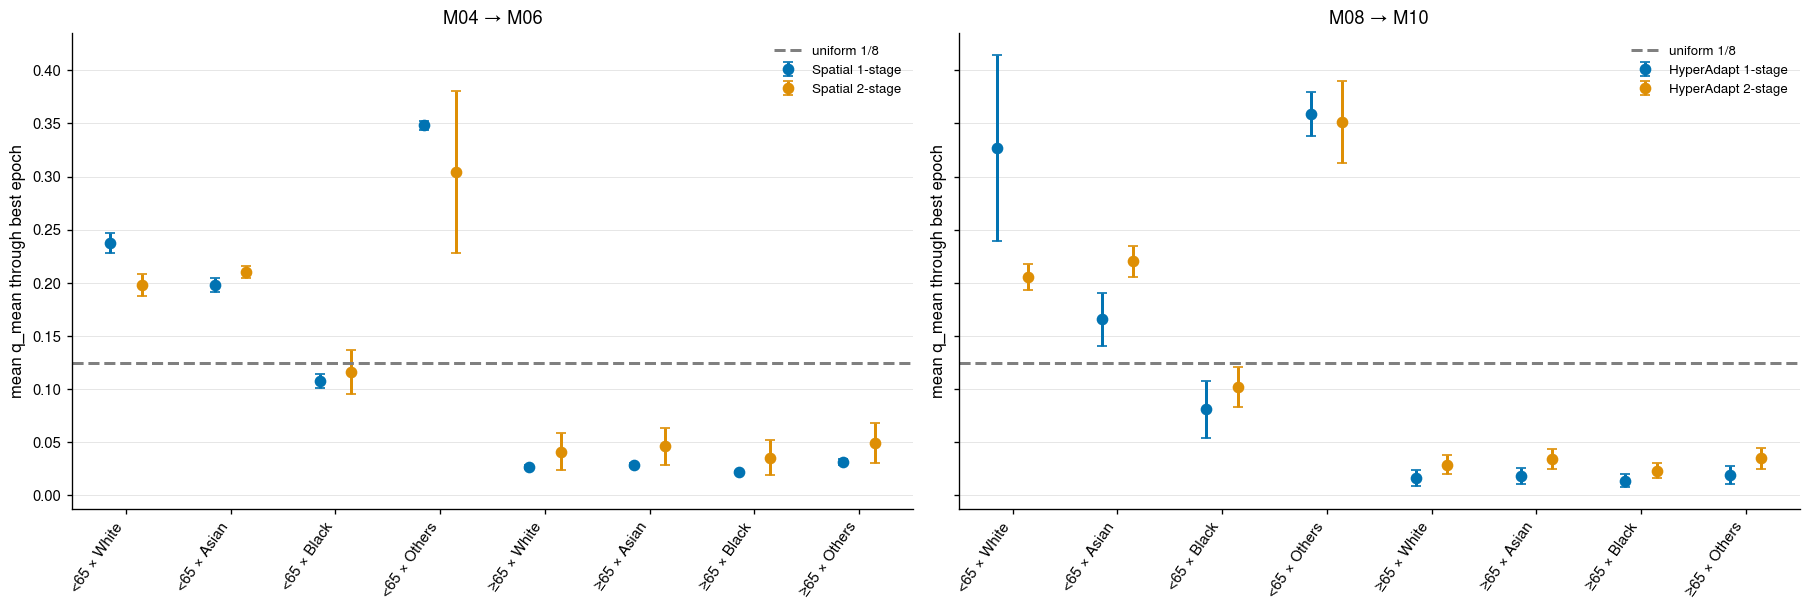

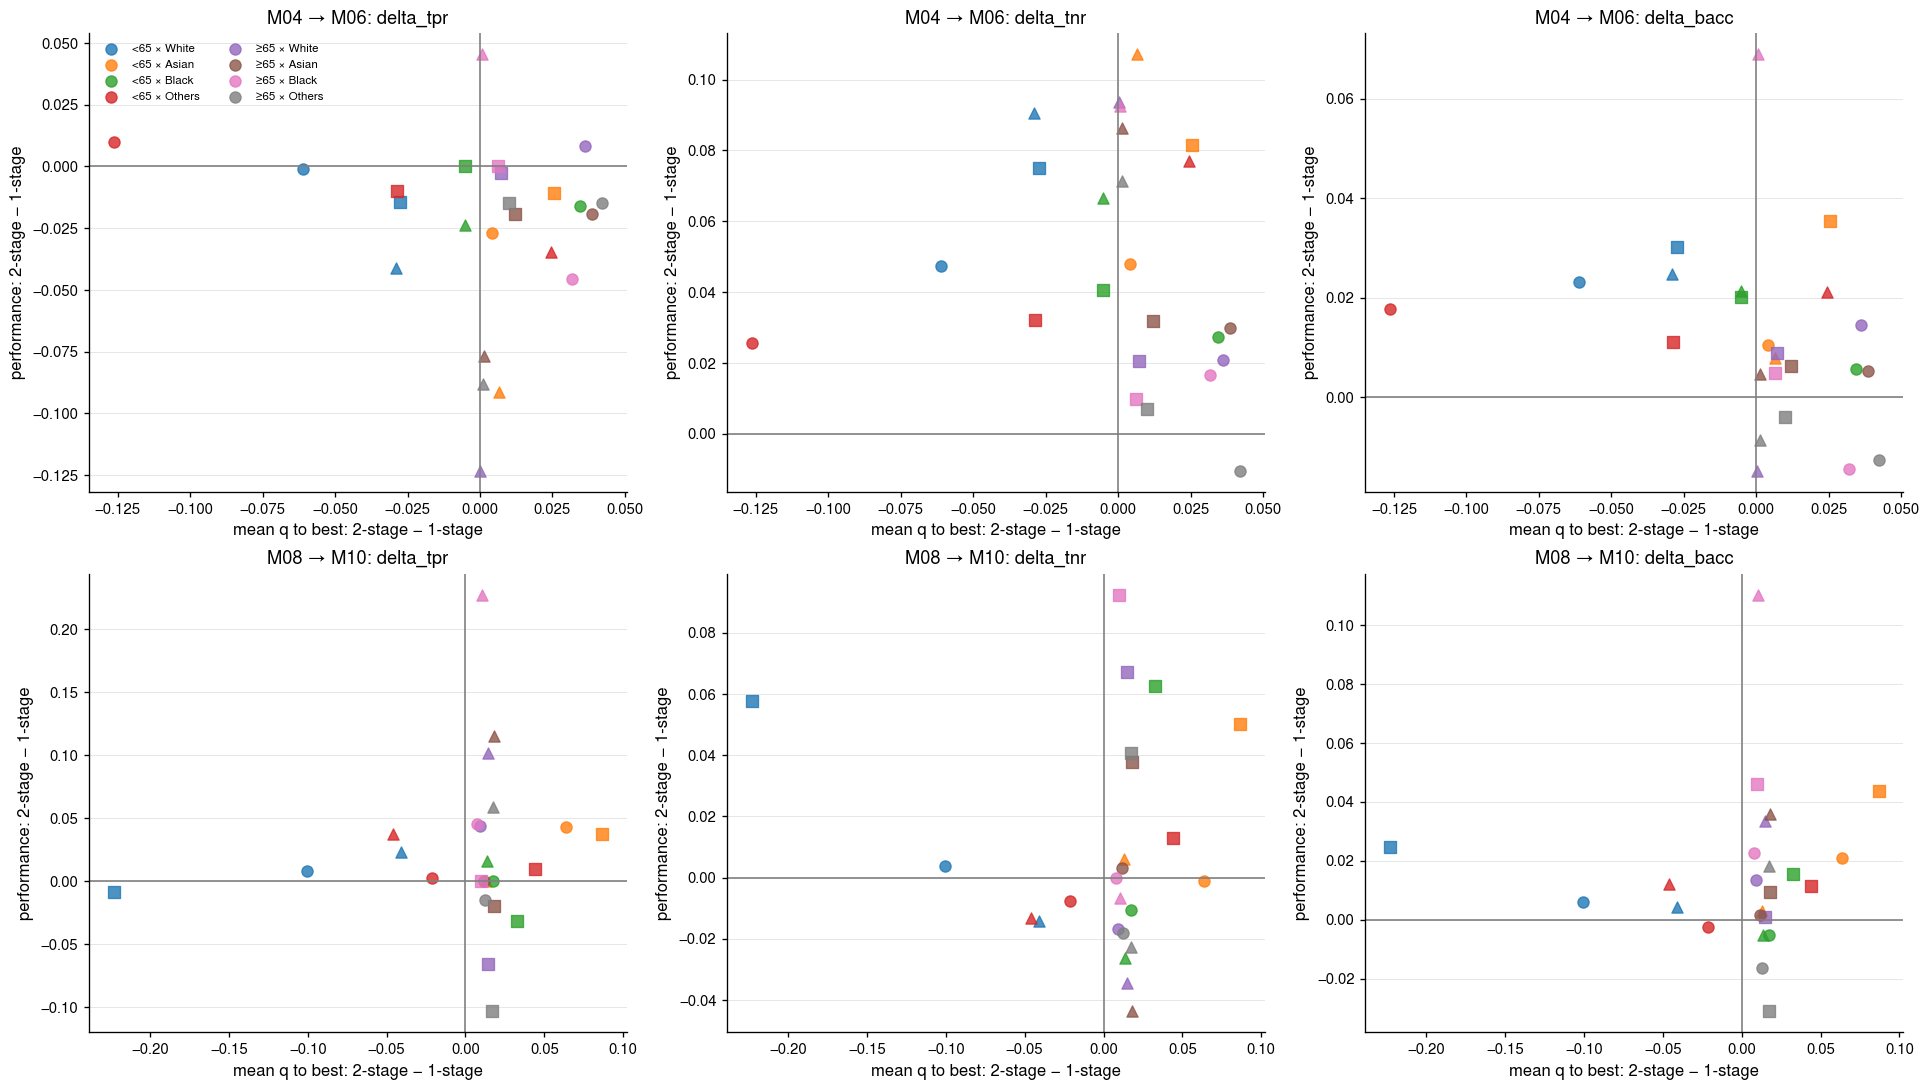

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), layout="constrained", sharey=True)
for ax, (baseline, treatment) in zip(axes, PAIRS, strict=True):
    for offset, condition in [(-0.15, baseline), (0.15, treatment)]:
        selected = q_summary[q_summary.condition == condition]
        stats = selected.groupby("group_id").q_mean_to_best.agg(["mean", "std"])
        ax.errorbar(
            stats.index + offset, stats["mean"], yerr=stats["std"], fmt="o", capsize=3, label=q_labels[condition]
        )
    ax.axhline(1 / 8, color="grey", linestyle="--", label="uniform 1/8")
    ax.set(title=f"{baseline} → {treatment}", ylabel="mean q_mean through best epoch")
    ax.set_xticks(range(8), GROUP_LABELS, rotation=55, ha="right")
    ax.legend(fontsize=8)
fig.savefig(FIGURES / "q_allocation_to_best.png", dpi=160)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 9), layout="constrained")
colors = plt.get_cmap("tab10").colors
for row, (baseline, treatment) in enumerate(PAIRS):
    selected = q_changes[q_changes.pair == f"{baseline} → {treatment}"]
    for col, metric in enumerate(["delta_tpr", "delta_tnr", "delta_bacc"]):
        ax = axes[row, col]
        for group, label in enumerate(GROUP_LABELS):
            for seed, marker in zip(SEEDS, ["o", "s", "^"], strict=True):
                data = selected[(selected.group_id == group) & (selected.seed == seed)]
                ax.scatter(
                    data.delta_q_mean_to_best,
                    data[metric],
                    color=colors[group],
                    marker=marker,
                    s=45,
                    alpha=0.8,
                    label=label if seed == SEEDS[0] else None,
                )
        ax.axhline(0, color="grey", linewidth=1)
        ax.axvline(0, color="grey", linewidth=1)
        ax.set(
            title=f"{baseline} → {treatment}: {metric}",
            xlabel="mean q to best: 2-stage − 1-stage",
            ylabel="performance: 2-stage − 1-stage",
        )
        if row == 0 and col == 0:
            ax.legend(fontsize=7, ncol=2)
fig.savefig(FIGURES / "delta_q_vs_group_changes.png", dpi=160)
plt.show()

## まとめ・TODO

bestまでのqは65歳未満4群へ集中（2-stageの3seed平均：Spatial 82.8%、HyperAdapt 87.9%）。≥65×Othersの平均qは1-stageより2-stageで全seed上昇するが、感度・BACCは平均で悪化。親ERMとの比較ではHyperAdaptの同群TPRは平均改善し、比較基準にも注意する。qが増えれば感度も改善する、という単純な対応ではない。

3seed平均では、Spatialの全体BACC改善はTPR側−0.0120をTNR側+0.0267が上回った結果。HyperAdaptはTPR側+0.0072・TNR側+0.0041が寄与。両モデルとも最小TPR群は≥65×Others（陽性68件）で、2-stageで平均TPRが低下する。Eopp0縮小は主に低TNR側の改善による。

群別率・gap両端・全体への寄与・判定変更を対応づけて読む。観察メモはreports/two_stage_operating_point.md。3seedのばらつきと少数陽性群に注意し、凍結やDRO単独の因果効果は主張しない。

TODO：陽性/陰性別CEと群lossの詳細診断、必要な群のスコア分布、閾値依存性、subgroup weightedでの再現確認。凍結解除の因果検証には別の追加実験が必要。